# Part B: Sentiment Classification for Women's Clothing Reviews

## Setup: Install Required Packages

In [ ]:
%pip install -q pandas matplotlib scikit-learn xgboost

In [1]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import LinearSVC
from IPython.display import display as notebook_display
from xgboost import XGBClassifier

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=ConvergenceWarning)

DATA_PATH = Path('../data/Womens Clothing E-Commerce Reviews.csv')
RANDOM_STATE = 42
SENTIMENT_ORDER = ['negative', 'neutral', 'positive']

pd.set_option('display.max_colwidth', 90)
pd.set_option('display.width', 140)
plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25

## Q1. Dataset Selection and Exploratory Data Analysis

In [2]:
def make_sentiment_label(rating: int) -> str:
    if rating <= 2:
        return 'negative'
    if rating == 3:
        return 'neutral'
    return 'positive'


def clean_text(text: str) -> str:
    text = re.sub(r'\s+', ' ', str(text)).strip()
    return text


def add_cleaning_step(records: list[dict], step: str, before_count: int, after_count: int) -> None:
    records.append({
        'Cleaning Step': step,
        'Rows Before': before_count,
        'Rows After': after_count,
        'Rows Removed': before_count - after_count,
    })


def prepare_reviews(path: Path) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    raw = pd.read_csv(path)
    raw = raw.rename(columns={raw.columns[0]: 'Original Row'})

    cleaning_records = []
    prepared = raw.copy()

    before_count = len(prepared)
    prepared = prepared[prepared['Rating'].notna()].copy()
    add_cleaning_step(cleaning_records, 'Remove rows with missing Rating', before_count, len(prepared))

    before_count = len(prepared)
    prepared = prepared[prepared['Rating'].between(1, 5)].copy()
    add_cleaning_step(cleaning_records, 'Remove rows with invalid Rating outside 1-5', before_count, len(prepared))

    before_count = len(prepared)
    prepared['Title'] = prepared['Title'].fillna('')
    prepared['Review Text'] = prepared['Review Text'].fillna('')
    prepared['text'] = (prepared['Title'] + ' ' + prepared['Review Text']).map(clean_text)
    add_cleaning_step(cleaning_records, 'Create combined text from Title and Review Text', before_count, len(prepared))

    before_count = len(prepared)
    prepared = prepared[prepared['text'].str.len() > 0].copy()
    add_cleaning_step(cleaning_records, 'Remove rows with empty combined text', before_count, len(prepared))

    before_count = len(prepared)
    prepared = prepared.drop_duplicates(subset=['text', 'Rating']).copy()
    add_cleaning_step(cleaning_records, 'Remove duplicate text-rating records', before_count, len(prepared))

    prepared['sentiment'] = prepared['Rating'].astype(int).map(make_sentiment_label)
    prepared['word_count'] = prepared['text'].str.split().str.len()
    prepared['character_count'] = prepared['text'].str.len()

    cleaning_log = pd.DataFrame(cleaning_records)
    return raw, prepared, cleaning_log


raw_reviews, reviews, cleaning_log = prepare_reviews(DATA_PATH)

overview = pd.DataFrame({
    'Metric': [
        'Original rows',
        'Rows after cleaning',
        'Rows removed',
        'Columns before cleaning',
        'Columns after cleaning',
        'Classification target',
        'Input text field',
    ],
    'Value': [
        f'{len(raw_reviews):,}',
        f'{len(reviews):,}',
        f'{len(raw_reviews) - len(reviews):,}',
        f'{raw_reviews.shape[1]:,}',
        f'{reviews.shape[1]:,}',
        'Sentiment derived from Rating',
        'Title + Review Text',
    ],
})
overview

,Metric,Value
0,Original rows,"23,486"
1,Rows after cleaning,"22,637"
2,Rows removed,849
3,Columns before cleaning,11
4,Columns after cleaning,15
5,Classification target,Sentiment derived from Rating
6,Input text field,Title + Review Text


### Data Cleaning Overview

The following tables show the number of records removed at each cleaning step and the final class distribution used for modelling.

In [3]:
cleaning_log_display = cleaning_log.copy()
for column in ['Rows Before', 'Rows After', 'Rows Removed']:
    cleaning_log_display[column] = cleaning_log_display[column].map(lambda value: f'{value:,}')

missing_before_after = pd.DataFrame({
    'Field': ['Title', 'Review Text', 'Rating'],
    'Missing Before Cleaning': [
        raw_reviews['Title'].isna().sum(),
        raw_reviews['Review Text'].isna().sum(),
        raw_reviews['Rating'].isna().sum(),
    ],
    'Missing After Cleaning': [
        reviews['Title'].isna().sum(),
        reviews['Review Text'].isna().sum(),
        reviews['Rating'].isna().sum(),
    ],
})

rating_before = raw_reviews['Rating'].value_counts().sort_index()
rating_after = reviews['Rating'].value_counts().sort_index()
rating_before_after = pd.DataFrame({
    'Rating': sorted(set(rating_before.index).union(set(rating_after.index))),
})
rating_before_after['Count Before Cleaning'] = rating_before_after['Rating'].map(rating_before).fillna(0).astype(int)
rating_before_after['Count After Cleaning'] = rating_before_after['Rating'].map(rating_after).fillna(0).astype(int)
rating_before_after['Rows Removed'] = rating_before_after['Count Before Cleaning'] - rating_before_after['Count After Cleaning']

sentiment_counts = (
    reviews['sentiment']
    .value_counts()
    .reindex(SENTIMENT_ORDER)
    .rename_axis('Sentiment')
    .reset_index(name='Count After Cleaning')
)
sentiment_counts['Share %'] = (sentiment_counts['Count After Cleaning'] / len(reviews) * 100).round(2)

print('Cleaning Log')
notebook_display(cleaning_log_display)
print('Missing Values')
notebook_display(missing_before_after)
print('Rating Counts')
notebook_display(rating_before_after)
print('Final Sentiment Counts')
notebook_display(sentiment_counts)

Cleaning Log


,Cleaning Step,Rows Before,Rows After,Rows Removed
0,Remove rows with missing Rating,"23,486","23,486",0
1,Remove rows with invalid Rating outside 1-5,"23,486","23,486",0
2,Create combined text from Title and Review Text,"23,486","23,486",0
3,Remove rows with empty combined text,"23,486","22,642",844
4,Remove duplicate text-rating records,"22,642","22,637",5


Missing Values


,Field,Missing Before Cleaning,Missing After Cleaning
0,Title,3810,0
1,Review Text,845,0
2,Rating,0,0


Rating Counts


,Rating,Count Before Cleaning,Count After Cleaning,Rows Removed
0,1,842,821,21
1,2,1565,1549,16
2,3,2871,2823,48
3,4,5077,4908,169
4,5,13131,12536,595


Final Sentiment Counts


,Sentiment,Count After Cleaning,Share %
0,negative,2370,10.47
1,neutral,2823,12.47
2,positive,17444,77.06


In [4]:
missing_summary = (
    raw_reviews.isna()
    .sum()
    .rename('Missing Values')
    .to_frame()
    .assign(**{'Missing %': lambda table: (table['Missing Values'] / len(raw_reviews) * 100).round(2)})
    .query('`Missing Values` > 0')
    .sort_values('Missing Values', ascending=False)
)
missing_summary

,Missing Values,Missing %
Title,3810,16.22
Review Text,845,3.60
Division Name,14,0.06
Department Name,14,0.06
Class Name,14,0.06


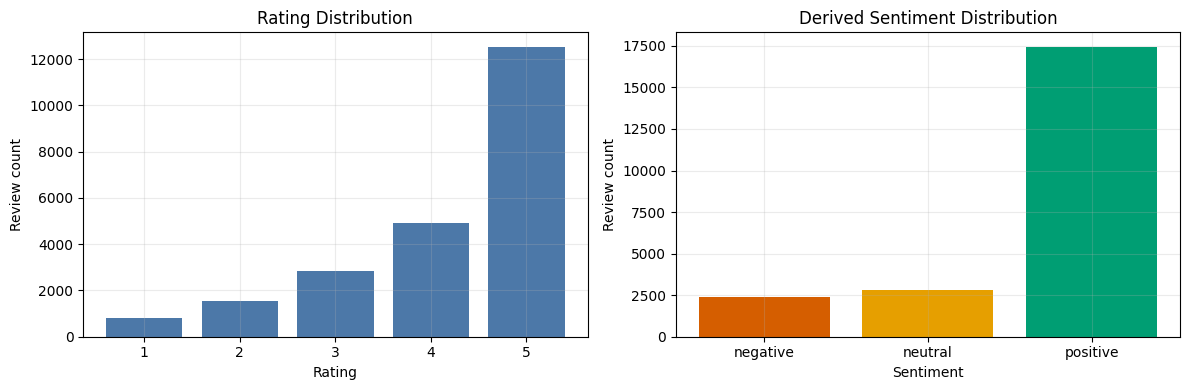

,Sentiment,Reviews,Share %
0,negative,2370,10.47
1,neutral,2823,12.47
2,positive,17444,77.06


In [5]:
rating_summary = (
    reviews['Rating']
    .value_counts()
    .sort_index()
    .rename_axis('Rating')
    .reset_index(name='Reviews')
)

sentiment_summary = (
    reviews['sentiment']
    .value_counts()
    .reindex(SENTIMENT_ORDER)
    .rename_axis('Sentiment')
    .reset_index(name='Reviews')
)
sentiment_summary['Share %'] = (sentiment_summary['Reviews'] / len(reviews) * 100).round(2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(rating_summary['Rating'].astype(str), rating_summary['Reviews'], color='#4C78A8')
axes[0].set_title('Rating Distribution')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Review count')

axes[1].bar(sentiment_summary['Sentiment'], sentiment_summary['Reviews'], color=['#D55E00', '#E69F00', '#009E73'])
axes[1].set_title('Derived Sentiment Distribution')
axes[1].set_xlabel('Sentiment')
axes[1].set_ylabel('Review count')
plt.tight_layout()
plt.show()

sentiment_summary

In [6]:
length_summary = (
    reviews.groupby('sentiment')[['word_count', 'character_count']]
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .round(2)
    .reindex(SENTIMENT_ORDER)
)
length_summary

word_count                        character_count                        
               count   mean median min  max           count    mean median min  max
sentiment                                                                          
negative        2370  63.98   63.0   6  118            2370  331.39  327.0  36  557
neutral         2823  67.61   68.0   3  117            2823  346.14  346.0  21  554
positive       17444  62.26   61.0   2  121           17444  321.73  313.0  11  552

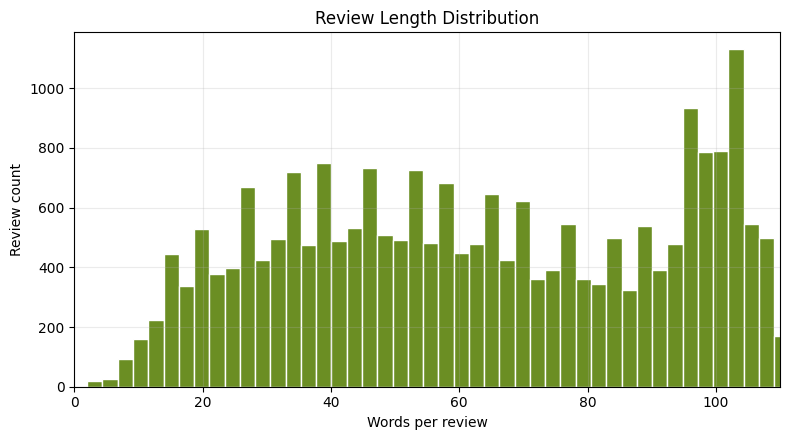

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(reviews['word_count'], bins=50, color='#6B8E23', edgecolor='white')
ax.set_title('Review Length Distribution')
ax.set_xlabel('Words per review')
ax.set_ylabel('Review count')
ax.set_xlim(0, reviews['word_count'].quantile(0.99))
plt.tight_layout()
plt.show()

In [8]:
category_summary = (
    reviews.groupby(['Department Name', 'sentiment'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=SENTIMENT_ORDER)
)
category_summary['total'] = category_summary.sum(axis=1)
category_summary = category_summary.sort_values('total', ascending=False)
category_summary.head(10)

sentiment,negative,neutral,positive,total
Department Name,,,,
Tops,1096,1300,7651,10047
Dresses,681,830,4635,6146
Bottoms,317,407,2937,3661
Intimate,147,177,1326,1650
Jackets,108,90,804,1002
Trend,21,19,78,118


In [9]:
vectorizer_for_eda = CountVectorizer(stop_words='english', min_df=5)
unigram_matrix = vectorizer_for_eda.fit_transform(reviews['text'])
unigram_counts = pd.Series(
    unigram_matrix.sum(axis=0).A1,
    index=vectorizer_for_eda.get_feature_names_out(),
).sort_values(ascending=False)

bigram_vectorizer_for_eda = CountVectorizer(stop_words='english', ngram_range=(2, 2), min_df=5)
bigram_matrix = bigram_vectorizer_for_eda.fit_transform(reviews['text'])
bigram_counts = pd.Series(
    bigram_matrix.sum(axis=0).A1,
    index=bigram_vectorizer_for_eda.get_feature_names_out(),
).sort_values(ascending=False)

vocabulary_summary = pd.DataFrame({
    'Measure': ['Usable reviews', 'Unique unigram terms', 'Unique bigram terms'],
    'Value': [f'{len(reviews):,}', f'{len(unigram_counts):,}', f'{len(bigram_counts):,}'],
})

pd.concat(
    [
        vocabulary_summary,
        pd.DataFrame({'Measure': ['Most frequent unigram', 'Most frequent bigram'], 'Value': [unigram_counts.index[0], bigram_counts.index[0]]}),
    ],
    ignore_index=True,
)

,Measure,Value
0,Usable reviews,"22,637"
1,Unique unigram terms,"4,774"
2,Unique bigram terms,"18,073"
3,Most frequent unigram,dress
4,Most frequent bigram,true size


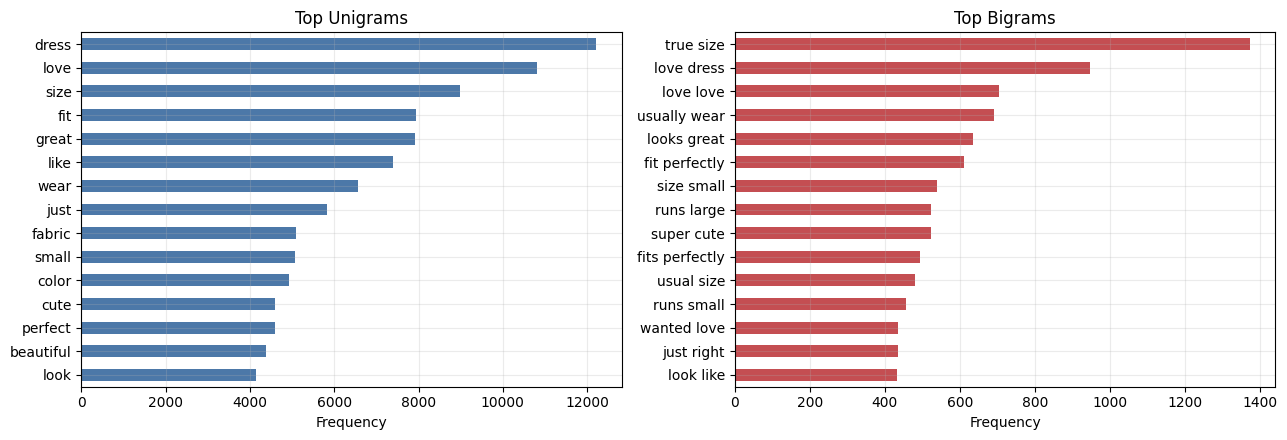

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
unigram_counts.head(15).sort_values().plot(kind='barh', ax=axes[0], color='#4C78A8')
axes[0].set_title('Top Unigrams')
axes[0].set_xlabel('Frequency')

bigram_counts.head(15).sort_values().plot(kind='barh', ax=axes[1], color='#C44E52')
axes[1].set_title('Top Bigrams')
axes[1].set_xlabel('Frequency')
plt.tight_layout()
plt.show()

## Q2. Supervised Text Classification Models

In [11]:
X = reviews['text']
y = reviews['sentiment']

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
label_mapping_table = pd.DataFrame({
    'Encoded Label': label_encoder.transform(SENTIMENT_ORDER),
    'Sentiment': SENTIMENT_ORDER,
})

X_train, X_test, y_train, y_test, y_train_encoded, y_test_encoded = train_test_split(
    X,
    y,
    y_encoded,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

split_summary = pd.DataFrame({
    'Split': ['Training set', 'Test set'],
    'Rows': [len(X_train), len(X_test)],
    'Share %': [round(len(X_train) / len(X) * 100, 2), round(len(X_test) / len(X) * 100, 2)],
})
notebook_display(split_summary)
notebook_display(label_mapping_table)

,Split,Rows,Share %
0,Training set,18109,80.0
1,Test set,4528,20.0


,Encoded Label,Sentiment
0,0,negative
1,1,neutral
2,2,positive


In [12]:
def make_text_pipeline(classifier) -> Pipeline:
    return Pipeline([
        ('tfidf', TfidfVectorizer(stop_words='english', min_df=2, max_features=5000, ngram_range=(1, 2))),
        ('model', classifier),
    ])


baseline_models = {
    'Complement Naive Bayes': make_text_pipeline(ComplementNB()),
    'Logistic Regression': make_text_pipeline(LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)),
    'LinearSVC': make_text_pipeline(LinearSVC(class_weight='balanced', random_state=RANDOM_STATE)),
    'XGBoost': make_text_pipeline(XGBClassifier(
        objective='multi:softmax',
        eval_metric='mlogloss',
        num_class=len(SENTIMENT_ORDER),
        n_estimators=120,
        max_depth=4,
        learning_rate=0.1,
        subsample=0.9,
        colsample_bytree=0.9,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
}


def model_target(model_name: str):
    if model_name == 'XGBoost':
        return y_train_encoded, y_test_encoded
    return y_train, y_test


def decode_predictions(model_name: str, predictions):
    if model_name == 'XGBoost':
        return label_encoder.inverse_transform(predictions.astype(int))
    return predictions


def evaluate_predictions(model_name: str, true_labels, predicted_labels) -> dict[str, float | str]:
    return {
        'Model': model_name,
        'Accuracy': accuracy_score(true_labels, predicted_labels),
        'Macro F1': f1_score(true_labels, predicted_labels, average='macro'),
        'Weighted F1': f1_score(true_labels, predicted_labels, average='weighted'),
    }


baseline_rows = []
baseline_predictions = {}

for name, model in baseline_models.items():
    train_target, _ = model_target(name)
    model.fit(X_train, train_target)
    predictions = decode_predictions(name, model.predict(X_test))
    baseline_predictions[name] = predictions
    baseline_rows.append(evaluate_predictions(name, y_test, predictions))

baseline_results = pd.DataFrame(baseline_rows).sort_values('Macro F1', ascending=False)
baseline_results[['Accuracy', 'Macro F1', 'Weighted F1']] = baseline_results[['Accuracy', 'Macro F1', 'Weighted F1']].round(4)
baseline_results

def evaluate_before_after_tuning(
    model_name: str,
    baseline_predictions,
    tuned_predictions,
    best_parameters: dict,
    best_cv_score: float,
) -> pd.DataFrame:
    before = evaluate_predictions(model_name, y_test, baseline_predictions)
    after = evaluate_predictions(model_name, y_test, tuned_predictions)
    return pd.DataFrame([
        {
            'Model': model_name,
            'Best Parameters': format_parameters(best_parameters),
            'Best CV Macro F1': round(best_cv_score, 4),
            'Accuracy Before Tuning': round(before['Accuracy'], 4),
            'Accuracy After Tuning': round(after['Accuracy'], 4),
            'Accuracy Change': round(after['Accuracy'] - before['Accuracy'], 4),
            'Macro F1 Before Tuning': round(before['Macro F1'], 4),
            'Macro F1 After Tuning': round(after['Macro F1'], 4),
            'Macro F1 Change': round(after['Macro F1'] - before['Macro F1'], 4),
            'Weighted F1 Before Tuning': round(before['Weighted F1'], 4),
            'Weighted F1 After Tuning': round(after['Weighted F1'], 4),
        }
    ])

def classification_report_table(true_labels, predicted_labels) -> pd.DataFrame:
    report = classification_report(
        true_labels,
        predicted_labels,
        labels=SENTIMENT_ORDER,
        output_dict=True,
        zero_division=0,
    )
    table = pd.DataFrame(report).T
    table = table.rename_axis('Class').reset_index()
    numeric_columns = ['precision', 'recall', 'f1-score']
    table[numeric_columns] = table[numeric_columns].round(4)
    table['support'] = table['support'].astype(int)
    return table

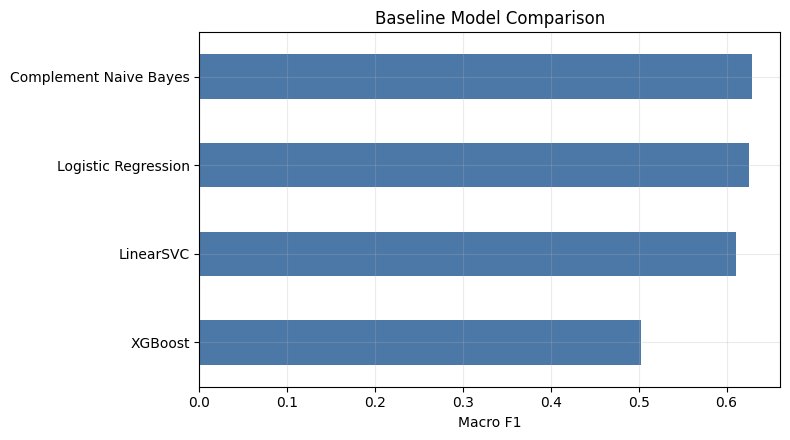

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
baseline_results.sort_values('Macro F1').plot(
    x='Model',
    y='Macro F1',
    kind='barh',
    legend=False,
    ax=ax,
    color='#4C78A8',
)
ax.set_title('Baseline Model Comparison')
ax.set_xlabel('Macro F1')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

#### Complement Naive Bayes: Original Classification Report and Confusion Matrix

,Class,precision,recall,f1-score,support
0,negative,0.4916,0.6793,0.5704,474
1,neutral,0.3731,0.4425,0.4049,565
2,positive,0.9535,0.8753,0.9127,3489
3,accuracy,0.8008,0.8008,0.8008,0
4,macro avg,0.6061,0.6657,0.6293,4528
5,weighted avg,0.8327,0.8008,0.8135,4528


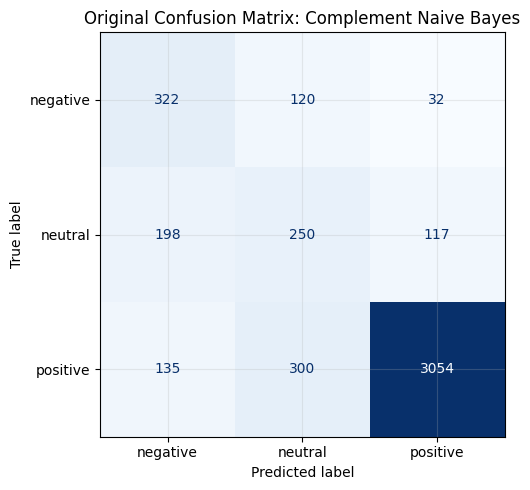

In [14]:
model_name = 'Complement Naive Bayes'
original_predictions = baseline_predictions[model_name]

notebook_display(classification_report_table(y_test, original_predictions))

cm = confusion_matrix(y_test, original_predictions, labels=SENTIMENT_ORDER)
matrix_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=SENTIMENT_ORDER)
fig, ax = plt.subplots(figsize=(6, 5))
matrix_display.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title(f'Original Confusion Matrix: {model_name}')
plt.tight_layout()
plt.show()

#### Logistic Regression: Original Classification Report and Confusion Matrix

,Class,precision,recall,f1-score,support
0,negative,0.5150,0.6139,0.5602,474
1,neutral,0.3409,0.5044,0.4069,565
2,positive,0.9607,0.8610,0.9081,3489
3,accuracy,0.7906,0.7906,0.7906,0
4,macro avg,0.6055,0.6598,0.6250,4528
5,weighted avg,0.8367,0.7906,0.8091,4528


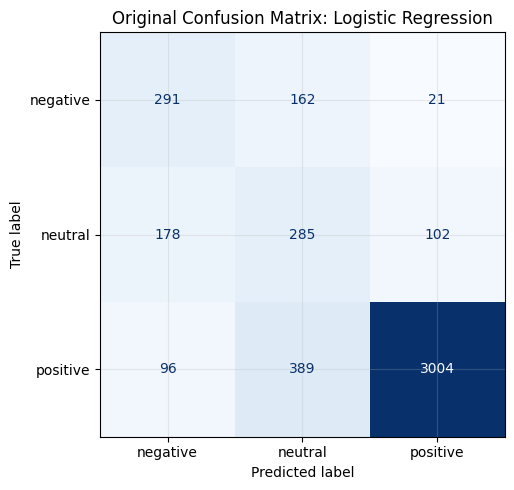

In [15]:
model_name = 'Logistic Regression'
original_predictions = baseline_predictions[model_name]

notebook_display(classification_report_table(y_test, original_predictions))

cm = confusion_matrix(y_test, original_predictions, labels=SENTIMENT_ORDER)
matrix_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=SENTIMENT_ORDER)
fig, ax = plt.subplots(figsize=(6, 5))
matrix_display.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title(f'Original Confusion Matrix: {model_name}')
plt.tight_layout()
plt.show()

#### LinearSVC: Original Classification Report and Confusion Matrix

,Class,precision,recall,f1-score,support
0,negative,0.5460,0.5506,0.5483,474
1,neutral,0.3540,0.3841,0.3684,565
2,positive,0.9235,0.9097,0.9165,3489
3,accuracy,0.8065,0.8065,0.8065,0
4,macro avg,0.6078,0.6148,0.6111,4528
5,weighted avg,0.8129,0.8065,0.8096,4528


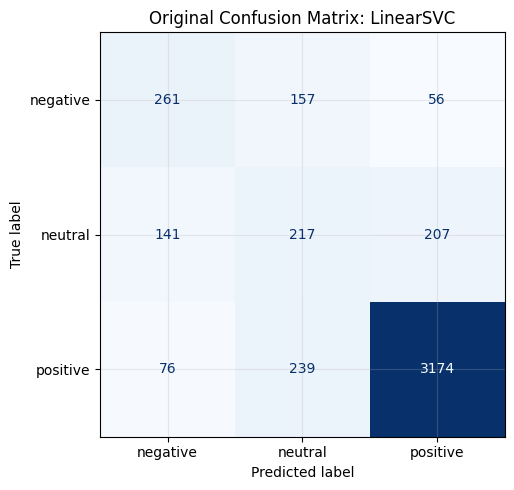

In [16]:
model_name = 'LinearSVC'
original_predictions = baseline_predictions[model_name]

notebook_display(classification_report_table(y_test, original_predictions))

cm = confusion_matrix(y_test, original_predictions, labels=SENTIMENT_ORDER)
matrix_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=SENTIMENT_ORDER)
fig, ax = plt.subplots(figsize=(6, 5))
matrix_display.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title(f'Original Confusion Matrix: {model_name}')
plt.tight_layout()
plt.show()

#### XGBoost: Original Classification Report and Confusion Matrix

,Class,precision,recall,f1-score,support
0,negative,0.6652,0.3228,0.4347,474
1,neutral,0.4478,0.1062,0.1717,565
2,positive,0.8295,0.9900,0.9027,3489
3,accuracy,0.8098,0.8098,0.8098,0
4,macro avg,0.6475,0.4730,0.5030,4528
5,weighted avg,0.7647,0.8098,0.7625,4528


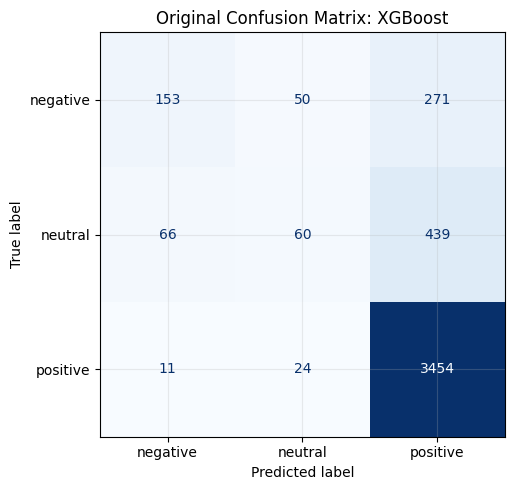

In [17]:
model_name = 'XGBoost'
original_predictions = baseline_predictions[model_name]

notebook_display(classification_report_table(y_test, original_predictions))

cm = confusion_matrix(y_test, original_predictions, labels=SENTIMENT_ORDER)
matrix_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=SENTIMENT_ORDER)
fig, ax = plt.subplots(figsize=(6, 5))
matrix_display.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title(f'Original Confusion Matrix: {model_name}')
plt.tight_layout()
plt.show()

## Q3. Hyperparameter Selection

In [18]:
hyperparameter_notes = pd.DataFrame([
    {'Model': 'Complement Naive Bayes', 'Hyperparameter': 'model__alpha'},
    {'Model': 'Complement Naive Bayes', 'Hyperparameter': 'model__fit_prior'},
    {'Model': 'Logistic Regression', 'Hyperparameter': 'model__C'},
    {'Model': 'Logistic Regression', 'Hyperparameter': 'model__solver'},
    {'Model': 'Logistic Regression', 'Hyperparameter': 'model__l1_ratio'},
    {'Model': 'LinearSVC', 'Hyperparameter': 'model__C'},
    {'Model': 'LinearSVC', 'Hyperparameter': 'model__loss'},
    {'Model': 'XGBoost', 'Hyperparameter': 'model__max_depth'},
    {'Model': 'XGBoost', 'Hyperparameter': 'model__learning_rate'},
    {'Model': 'XGBoost', 'Hyperparameter': 'model__n_estimators'},
    {'Model': 'XGBoost', 'Hyperparameter': 'model__subsample'},
])
hyperparameter_notes

,Model,Hyperparameter
0,Complement Naive Bayes,model__alpha
1,Complement Naive Bayes,model__fit_prior
2,Logistic Regression,model__C
3,Logistic Regression,model__solver
4,Logistic Regression,model__l1_ratio
5,LinearSVC,model__C
6,LinearSVC,model__loss
7,XGBoost,model__max_depth
8,XGBoost,model__learning_rate
9,XGBoost,model__n_estimators


In [19]:
best_models = {}
tuned_predictions = {}


def format_parameters(parameters: dict) -> str:
    return ', '.join(f'{key}={value}' for key, value in parameters.items())

### Complement Naive Bayes Hyperparameter Tuning

In [20]:
complement_nb_search = GridSearchCV(
    estimator=make_text_pipeline(ComplementNB()),
    param_grid={'model__alpha': [0.1, 0.5, 1.0], 'model__fit_prior': [True, False]},
    scoring='f1_macro',
    cv=3,
    n_jobs=-1,
)
complement_nb_search.fit(X_train, y_train)
best_models['Complement Naive Bayes'] = complement_nb_search.best_estimator_

def summarize_search_results(search: GridSearchCV) -> pd.DataFrame:
    results = pd.DataFrame(search.cv_results_)[['params', 'mean_test_score', 'rank_test_score']].copy()
    parameter_columns = pd.json_normalize(results['params']).rename(
        columns=lambda column: column.replace('model__', '')
    )
    summary = pd.concat(
        [
            parameter_columns,
            results[['mean_test_score', 'rank_test_score']],
        ],
        axis=1,
    )
    summary = summary.rename(
        columns={
            'mean_test_score': 'CV Macro F1',
            'rank_test_score': 'Rank',
        }
    )
    summary['CV Macro F1'] = summary['CV Macro F1'].round(4)
    return summary.sort_values('Rank')

complement_nb_tuning_results = summarize_search_results(complement_nb_search)
complement_nb_tuning_results

,alpha,fit_prior,CV Macro F1,Rank
4,1.0,True,0.6089,1
5,1.0,False,0.6089,1
2,0.5,True,0.6060,3
3,0.5,False,0.6060,3
0,0.1,True,0.6057,5
1,0.1,False,0.6057,5


In [21]:
complement_nb_tuned_predictions = complement_nb_search.best_estimator_.predict(X_test)
tuned_predictions['Complement Naive Bayes'] = complement_nb_tuned_predictions

evaluate_before_after_tuning(
    model_name='Complement Naive Bayes',
    baseline_predictions=baseline_predictions['Complement Naive Bayes'],
    tuned_predictions=complement_nb_tuned_predictions,
    best_parameters=complement_nb_search.best_params_,
    best_cv_score=complement_nb_search.best_score_,
)

,Model,Best Parameters,Best CV Macro F1,Accuracy Before Tuning,Accuracy After Tuning,Accuracy Change,Macro F1 Before Tuning,Macro F1 After Tuning,Macro F1 Change,Weighted F1 Before Tuning,Weighted F1 After Tuning
0,Complement Naive Bayes,"model__alpha=1.0, model__fit_prior=True",0.6089,0.8008,0.8008,0.0,0.6293,0.6293,0.0,0.8135,0.8135


### Logistic Regression Hyperparameter Tuning

In [22]:
logistic_regression_search = GridSearchCV(
    estimator=make_text_pipeline(LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)),
    param_grid=[
        {'model__solver': ['saga'], 'model__l1_ratio': [0.0, 1.0], 'model__C': [0.5, 1.0, 2.0]},
        {'model__solver': ['lbfgs'], 'model__l1_ratio': [0.0], 'model__C': [0.5, 1.0, 2.0]},
    ],
    scoring='f1_macro',
    cv=3,
    n_jobs=-1,
)
logistic_regression_search.fit(X_train, y_train)
best_models['Logistic Regression'] = logistic_regression_search.best_estimator_

logistic_regression_tuning_results = summarize_search_results(logistic_regression_search)
logistic_regression_tuning_results

,C,l1_ratio,solver,CV Macro F1,Rank
7,1.0,0.0,lbfgs,0.6216,1
6,0.5,0.0,lbfgs,0.6202,2
8,2.0,0.0,lbfgs,0.6151,3
2,1.0,0.0,saga,0.5632,4
0,0.5,0.0,saga,0.5518,5
4,2.0,0.0,saga,0.5439,6
5,2.0,1.0,saga,0.5427,7
1,0.5,1.0,saga,0.5390,8
3,1.0,1.0,saga,0.5368,9


In [23]:
logistic_regression_tuned_predictions = logistic_regression_search.best_estimator_.predict(X_test)
tuned_predictions['Logistic Regression'] = logistic_regression_tuned_predictions

evaluate_before_after_tuning(
    model_name='Logistic Regression',
    baseline_predictions=baseline_predictions['Logistic Regression'],
    tuned_predictions=logistic_regression_tuned_predictions,
    best_parameters=logistic_regression_search.best_params_,
    best_cv_score=logistic_regression_search.best_score_,
)

,Model,Best Parameters,Best CV Macro F1,Accuracy Before Tuning,Accuracy After Tuning,Accuracy Change,Macro F1 Before Tuning,Macro F1 After Tuning,Macro F1 Change,Weighted F1 Before Tuning,Weighted F1 After Tuning
0,Logistic Regression,"model__C=1.0, model__l1_ratio=0.0, model__solver=lbfgs",0.6216,0.7906,0.7906,0.0,0.625,0.625,0.0,0.8091,0.8091


### LinearSVC Hyperparameter Tuning

In [24]:
linear_svc_search = GridSearchCV(
    estimator=make_text_pipeline(LinearSVC(class_weight='balanced', random_state=RANDOM_STATE)),
    param_grid=[
        {'model__C': [0.5, 1.0, 2.0], 'model__loss': ['squared_hinge']},
        {'model__C': [0.5, 1.0, 2.0], 'model__loss': ['hinge'], 'model__dual': [True]},
    ],
    scoring='f1_macro',
    cv=3,
    n_jobs=-1,
)
linear_svc_search.fit(X_train, y_train)
best_models['LinearSVC'] = linear_svc_search.best_estimator_

linear_svc_tuning_results = summarize_search_results(linear_svc_search)
linear_svc_tuning_results

,C,loss,dual,CV Macro F1,Rank
3,0.5,hinge,True,0.6242,1
4,1.0,hinge,True,0.6174,2
0,0.5,squared_hinge,NaN,0.6158,3
5,2.0,hinge,True,0.6069,4
1,1.0,squared_hinge,NaN,0.6050,5
2,2.0,squared_hinge,NaN,0.5963,6


In [25]:
linear_svc_tuned_predictions = linear_svc_search.best_estimator_.predict(X_test)
tuned_predictions['LinearSVC'] = linear_svc_tuned_predictions

evaluate_before_after_tuning(
    model_name='LinearSVC',
    baseline_predictions=baseline_predictions['LinearSVC'],
    tuned_predictions=linear_svc_tuned_predictions,
    best_parameters=linear_svc_search.best_params_,
    best_cv_score=linear_svc_search.best_score_,
)

,Model,Best Parameters,Best CV Macro F1,Accuracy Before Tuning,Accuracy After Tuning,Accuracy Change,Macro F1 Before Tuning,Macro F1 After Tuning,Macro F1 Change,Weighted F1 Before Tuning,Weighted F1 After Tuning
0,LinearSVC,"model__C=0.5, model__dual=True, model__loss=hinge",0.6242,0.8065,0.8291,0.0225,0.6111,0.6422,0.0311,0.8096,0.8292


### XGBoost Hyperparameter Tuning

In [26]:
xgboost_search = GridSearchCV(
    estimator=make_text_pipeline(XGBClassifier(
        objective='multi:softmax',
        eval_metric='mlogloss',
        num_class=len(SENTIMENT_ORDER),
        n_estimators=120,
        subsample=0.9,
        colsample_bytree=0.9,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
    param_grid={
        'model__max_depth': [3, 4],
        'model__learning_rate': [0.05, 0.1],
        'model__n_estimators': [100, 150],
        'model__subsample': [0.8, 1.0],
    },
    scoring='f1_macro',
    cv=3,
    n_jobs=-1,
)
xgboost_search.fit(X_train, y_train_encoded)
best_models['XGBoost'] = xgboost_search.best_estimator_

xgboost_tuning_results = summarize_search_results(xgboost_search)
xgboost_tuning_results

,learning_rate,max_depth,n_estimators,subsample,CV Macro F1,Rank
14,0.10,4,150,0.8,0.5103,1
15,0.10,4,150,1.0,0.5055,2
10,0.10,3,150,0.8,0.4976,3
11,0.10,3,150,1.0,0.4903,4
12,0.10,4,100,0.8,0.4878,5
13,0.10,4,100,1.0,0.4819,6
8,0.10,3,100,0.8,0.4673,7
6,0.05,4,150,0.8,0.4669,8
7,0.05,4,150,1.0,0.4605,9
9,0.10,3,100,1.0,0.4582,10


In [27]:
xgboost_tuned_predictions = decode_predictions('XGBoost', xgboost_search.best_estimator_.predict(X_test))
tuned_predictions['XGBoost'] = xgboost_tuned_predictions

evaluate_before_after_tuning(
    model_name='XGBoost',
    baseline_predictions=baseline_predictions['XGBoost'],
    tuned_predictions=xgboost_tuned_predictions,
    best_parameters=xgboost_search.best_params_,
    best_cv_score=xgboost_search.best_score_,
)

,Model,Best Parameters,Best CV Macro F1,Accuracy Before Tuning,Accuracy After Tuning,Accuracy Change,Macro F1 Before Tuning,Macro F1 After Tuning,Macro F1 Change,Weighted F1 Before Tuning,Weighted F1 After Tuning
0,XGBoost,"model__learning_rate=0.1, model__max_depth=4, model__n_estimators=150, model__subsampl...",0.5103,0.8098,0.8107,0.0009,0.503,0.5106,0.0076,0.7625,0.767


## Q4. Evaluation and Discussion

In [28]:
tuned_rows = []

for name in ['Complement Naive Bayes', 'Logistic Regression', 'LinearSVC', 'XGBoost']:
    tuned_rows.append(evaluate_predictions(name, y_test, tuned_predictions[name]))

tuned_results = pd.DataFrame(tuned_rows).sort_values('Macro F1', ascending=False)
tuned_results[['Accuracy', 'Macro F1', 'Weighted F1']] = tuned_results[['Accuracy', 'Macro F1', 'Weighted F1']].round(4)
tuned_results

,Model,Accuracy,Macro F1,Weighted F1
2,LinearSVC,0.8291,0.6422,0.8292
0,Complement Naive Bayes,0.8008,0.6293,0.8135
1,Logistic Regression,0.7906,0.6250,0.8091
3,XGBoost,0.8107,0.5106,0.7670


In [29]:
consolidated_tuning_summary = baseline_results.merge(
    tuned_results,
    on='Model',
    suffixes=(' Before Tuning', ' After Tuning'),
)
consolidated_tuning_summary['Macro F1 Change'] = (
    consolidated_tuning_summary['Macro F1 After Tuning'] - consolidated_tuning_summary['Macro F1 Before Tuning']
).round(4)
consolidated_tuning_summary[[
    'Model',
    'Macro F1 Before Tuning',
    'Macro F1 After Tuning',
    'Macro F1 Change',
    'Accuracy Before Tuning',
    'Accuracy After Tuning',
    'Weighted F1 Before Tuning',
    'Weighted F1 After Tuning',
]]

,Model,Macro F1 Before Tuning,Macro F1 After Tuning,Macro F1 Change,Accuracy Before Tuning,Accuracy After Tuning,Weighted F1 Before Tuning,Weighted F1 After Tuning
0,Complement Naive Bayes,0.6293,0.6293,0.0000,0.8008,0.8008,0.8135,0.8135
1,Logistic Regression,0.6250,0.6250,0.0000,0.7906,0.7906,0.8091,0.8091
2,LinearSVC,0.6111,0.6422,0.0311,0.8065,0.8291,0.8096,0.8292
3,XGBoost,0.5030,0.5106,0.0076,0.8098,0.8107,0.7625,0.7670


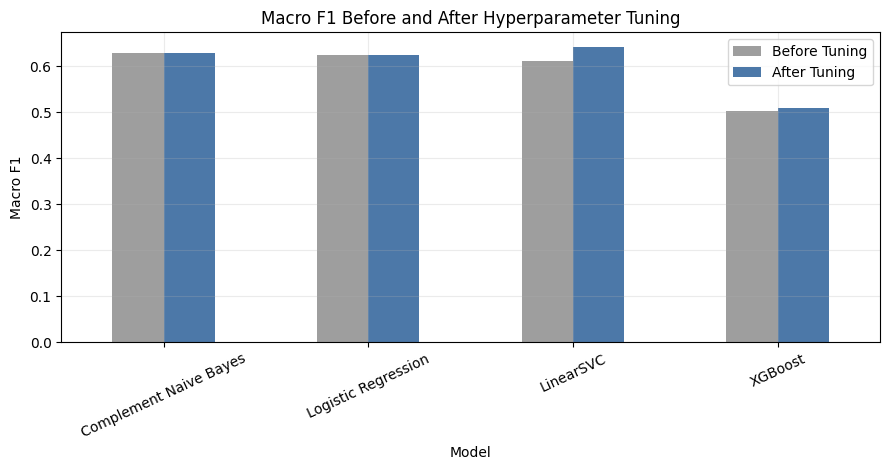

In [30]:
plot_data = consolidated_tuning_summary.set_index('Model')[[
    'Macro F1 Before Tuning',
    'Macro F1 After Tuning',
]]

fig, ax = plt.subplots(figsize=(9, 4.8))
plot_data.plot(kind='bar', ax=ax, color=['#9E9E9E', '#4C78A8'])
ax.set_title('Macro F1 Before and After Hyperparameter Tuning')
ax.set_xlabel('Model')
ax.set_ylabel('Macro F1')
ax.tick_params(axis='x', rotation=25)
ax.legend(['Before Tuning', 'After Tuning'])
plt.tight_layout()
plt.show()

### Complement Naive Bayes: Tuned Classification Report and Confusion Matrix

,Class,precision,recall,f1-score,support
0,negative,0.4916,0.6793,0.5704,474
1,neutral,0.3731,0.4425,0.4049,565
2,positive,0.9535,0.8753,0.9127,3489
3,accuracy,0.8008,0.8008,0.8008,0
4,macro avg,0.6061,0.6657,0.6293,4528
5,weighted avg,0.8327,0.8008,0.8135,4528


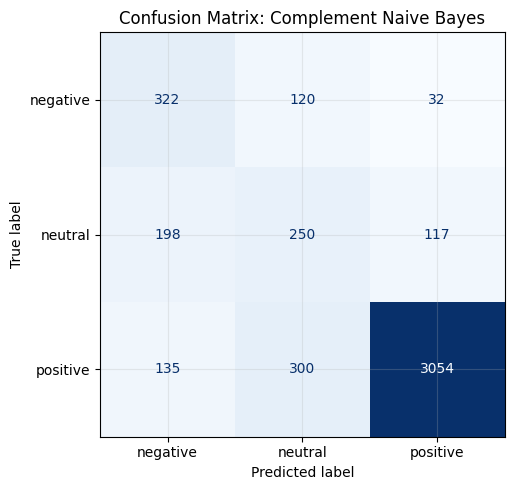

In [31]:
model_name = 'Complement Naive Bayes'
predictions = tuned_predictions[model_name]

notebook_display(classification_report_table(y_test, predictions))

cm = confusion_matrix(y_test, predictions, labels=SENTIMENT_ORDER)
matrix_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=SENTIMENT_ORDER)
fig, ax = plt.subplots(figsize=(6, 5))
matrix_display.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title(f'Confusion Matrix: {model_name}')
plt.tight_layout()
plt.show()

### Logistic Regression: Tuned Classification Report and Confusion Matrix

,Class,precision,recall,f1-score,support
0,negative,0.5150,0.6139,0.5602,474
1,neutral,0.3409,0.5044,0.4069,565
2,positive,0.9607,0.8610,0.9081,3489
3,accuracy,0.7906,0.7906,0.7906,0
4,macro avg,0.6055,0.6598,0.6250,4528
5,weighted avg,0.8367,0.7906,0.8091,4528


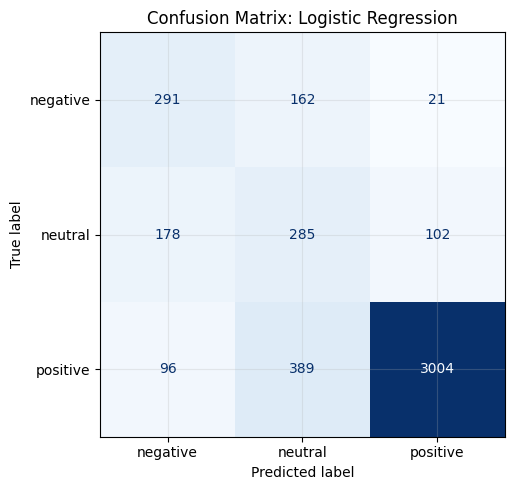

In [32]:
model_name = 'Logistic Regression'
predictions = tuned_predictions[model_name]

notebook_display(classification_report_table(y_test, predictions))

cm = confusion_matrix(y_test, predictions, labels=SENTIMENT_ORDER)
matrix_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=SENTIMENT_ORDER)
fig, ax = plt.subplots(figsize=(6, 5))
matrix_display.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title(f'Confusion Matrix: {model_name}')
plt.tight_layout()
plt.show()

### LinearSVC: Tuned Classification Report and Confusion Matrix

,Class,precision,recall,f1-score,support
0,negative,0.5827,0.6097,0.5959,474
1,neutral,0.4043,0.3965,0.4004,565
2,positive,0.9319,0.9289,0.9304,3489
3,accuracy,0.8291,0.8291,0.8291,0
4,macro avg,0.6396,0.6450,0.6422,4528
5,weighted avg,0.8295,0.8291,0.8292,4528


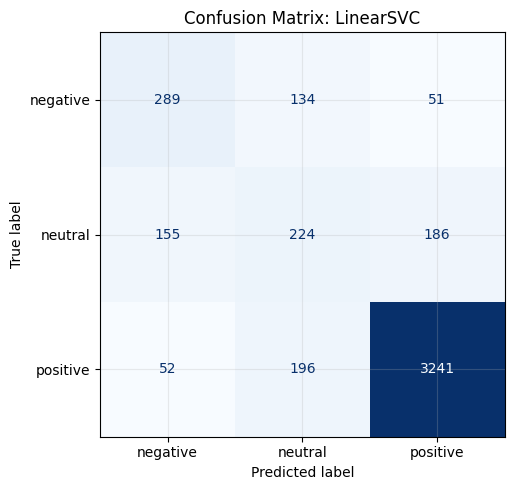

In [33]:
model_name = 'LinearSVC'
predictions = tuned_predictions[model_name]

notebook_display(classification_report_table(y_test, predictions))

cm = confusion_matrix(y_test, predictions, labels=SENTIMENT_ORDER)
matrix_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=SENTIMENT_ORDER)
fig, ax = plt.subplots(figsize=(6, 5))
matrix_display.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title(f'Confusion Matrix: {model_name}')
plt.tight_layout()
plt.show()

### XGBoost: Tuned Classification Report and Confusion Matrix

,Class,precision,recall,f1-score,support
0,negative,0.6494,0.3439,0.4497,474
1,neutral,0.3975,0.1133,0.1763,565
2,positive,0.8367,0.9871,0.9057,3489
3,accuracy,0.8107,0.8107,0.8107,0
4,macro avg,0.6279,0.4814,0.5106,4528
5,weighted avg,0.7623,0.8107,0.7670,4528


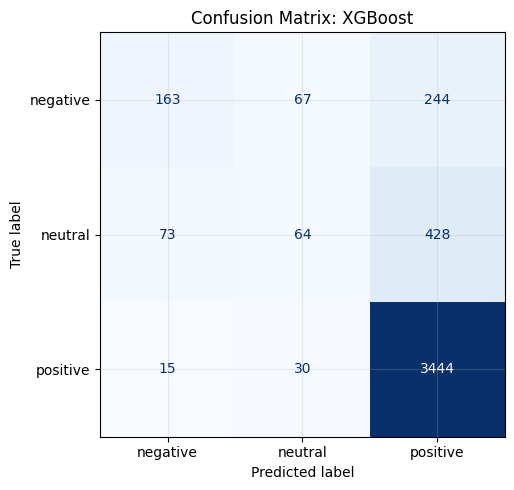

In [34]:
model_name = 'XGBoost'
predictions = tuned_predictions[model_name]

notebook_display(classification_report_table(y_test, predictions))

cm = confusion_matrix(y_test, predictions, labels=SENTIMENT_ORDER)
matrix_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=SENTIMENT_ORDER)
fig, ax = plt.subplots(figsize=(6, 5))
matrix_display.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title(f'Confusion Matrix: {model_name}')
plt.tight_layout()
plt.show()

### Final Tuned Model Comparison

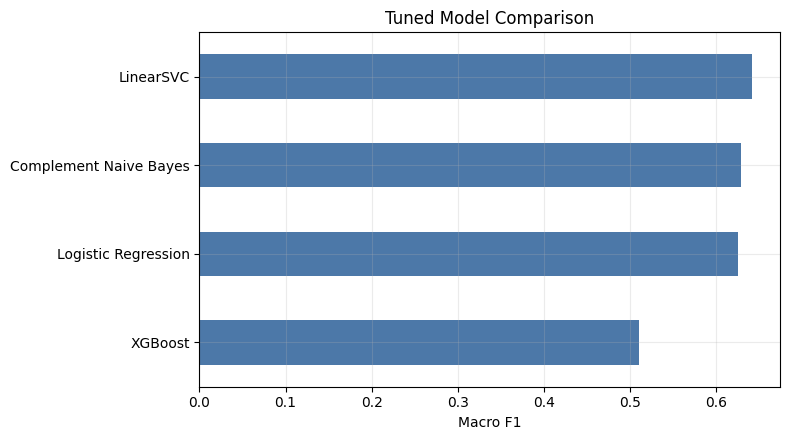

In [35]:
fig, ax = plt.subplots(figsize=(8, 4.5))
tuned_results.sort_values('Macro F1').plot(
    x='Model',
    y='Macro F1',
    kind='barh',
    legend=False,
    ax=ax,
    color='#4C78A8',
)
ax.set_title('Tuned Model Comparison')
ax.set_xlabel('Macro F1')
ax.set_ylabel('')
plt.tight_layout()
plt.show()